Wyciąganie utworów ze slakh

Przygotowanie danych do uczenia sieci w rozpoznawaniu instrumentów w nagraniach polifonicznych

In [ ]:
import tarfile
import yaml
from pathlib import PurePosixPath, Path
from collections import Counter, defaultdict
import pandas as pd
import shutil
import re
import csv
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
import random
from itertools import combinations

random.seed(258882)

In [ ]:
BASE_DIR= Path(__file__).resolve().parent
ARCHIVE = BASE_DIR / "slakh2100_flac_redux.tar.gz"
METADATA_DIR = BASE_DIR / "metadata_only"

1. Wyciągnięcie z archiwum "slakh2100_flac_redux.tar.gz" metadanych dotyczących utworów - zawierających informacje o tym jakie intrumenty w nim grają.

In [4]:
# Odczytaj archiwum bez wypakowywania plików audio
with tarfile.open(ARCHIVE, "r:gz") as archive:
    for member in archive:
        path = PurePosixPath(member.name)

        # Wybierz wyłącznie pliki metadata.yaml
        if member.isfile() and path.name == "metadata.yaml":
            # Zachowaj oryginalną strukturę katalogów
            destination = METADATA_DIR.joinpath(*path.parts)
            destination.parent.mkdir(parents=True, exist_ok=True)

            # Zapisz metadane na dysku
            with archive.extractfile(member) as source:
                destination.write_bytes(source.read())

1.1 Usunięcie katalogu ommited

In [27]:
for p in METADATA_DIR.rglob("*"):
    if p.is_dir() and p.name.lower() == "omitted":
        shutil.rmtree(p)
        
metadata_files = sorted(
    p for p in METADATA_DIR.rglob("metadata.yaml")
    if "omitted" not in p.parts
)

2. Statystyki dotyczące instrumentów

In [11]:
programs = Counter()
classes = Counter()
songs = []

for file in METADATA_DIR.rglob("metadata.yaml"):
    with file.open("r", encoding="utf-8") as f:
        metadata = yaml.safe_load(f) or {}

    stems = metadata.get("stems", {})
    names = []
    inst_classes = []

    for stem in stems.values():
        if not isinstance(stem, dict):
            continue

        # Zliczanie konkretnych instrumentów
        name = stem.get("midi_program_name")
        if name:
            programs[name] += 1
            names.append(name)

        # Zliczanie klas instrumentów
        inst_class = stem.get("inst_class")
        if inst_class:
            classes[inst_class] += 1
            inst_classes.append(inst_class)

    # Statystyki dla każdego utworu
    songs.append({
        "Utwór": str(file.relative_to(METADATA_DIR).parent),
        "Liczba ścieżek": len(stems),
        "Liczba instrumentów": len(names),
        "Liczba unikatowych instrumentów": len(set(names)),
        "Liczba unikatowych klas": len(set(inst_classes))
    })

# Tabela liczności i częstości konkretnych instrumentów
table_programs = pd.DataFrame(
    programs.items(), columns=["Instrument", "Liczność"]
)
table_programs["Częstość (%)"] = (
    table_programs["Liczność"] / sum(programs.values()) * 100
)
table_programs = table_programs.sort_values(
    "Liczność", ascending=False
).reset_index(drop=True)

# Tabela liczności i częstości klas instrumentów
table_classes = pd.DataFrame(
    classes.items(), columns=["Klasa", "Liczność"]
)
table_classes["Częstość (%)"] = (
    table_classes["Liczność"] / sum(classes.values()) * 100
)
table_classes = table_classes.sort_values(
    "Liczność", ascending=False
).reset_index(drop=True)

# Tabela statystyk dla każdego utworu
table_songs = pd.DataFrame(songs).sort_values(
    "Liczba ścieżek", ascending=False
).reset_index(drop=True)

# Rozkład liczby ścieżek na utwór
distribution_stems = (
    table_songs["Liczba ścieżek"]
    .value_counts()
    .sort_index()
    .rename_axis("Liczba ścieżek")
    .reset_index(name="Liczba utworów")
)
distribution_stems["Częstość (%)"] = (
    distribution_stems["Liczba utworów"] / len(table_songs) * 100
)

# Rozkład liczby unikatowych instrumentów na utwór
distribution_instruments = (
    table_songs["Liczba unikatowych instrumentów"]
    .value_counts()
    .sort_index()
    .rename_axis("Liczba unikatowych instrumentów")
    .reset_index(name="Liczba utworów")
)
distribution_instruments["Częstość (%)"] = (
    distribution_instruments["Liczba utworów"] / len(table_songs) * 100
)

# Wyświetlenie tabel
display(table_programs)
display(table_classes)
display(table_songs)
display(distribution_stems)
display(distribution_instruments)

,Instrument,Liczność,Częstość (%)
0,Drums,2100,8.927812
1,Acoustic Guitar (steel),1337,5.684040
2,String Ensemble 1,1103,4.689227
3,Electric Bass (finger),1052,4.472409
4,Electric Guitar (clean),957,4.068532
...,...,...,...
124,Bird Tweet,5,0.021257
125,Agogo,5,0.021257
126,Lead 7 (fifths),4,0.017005
127,Breath Noise,4,0.017005


,Klasa,Liczność,Częstość (%)
0,Guitar,5427,23.072018
1,Piano,3495,14.858430
2,Strings (continued),3366,14.310008
3,Bass,2500,10.628348
4,Drums,2100,8.927812
5,Brass,1078,4.582944
6,Synth Pad,941,4.000510
7,Reed,801,3.405323
8,Organ,745,3.167248
9,Pipe,721,3.065216


,Utwór,Liczba ścieżek,Liczba instrumentów,Liczba unikatowych instrumentów,Liczba unikatowych klas
0,slakh2100_flac_redux\validation\Track01590,48,48,26,12
1,slakh2100_flac_redux\train\Track00869,44,44,18,7
2,slakh2100_flac_redux\train\Track01297,25,25,21,10
3,slakh2100_flac_redux\train\Track00682,25,25,21,10
4,slakh2100_flac_redux\train\Track00598,25,25,20,11
...,...,...,...,...,...
2095,slakh2100_flac_redux\omitted\Track01544,5,5,5,4
2096,slakh2100_flac_redux\train\Track00889,5,5,4,4
2097,slakh2100_flac_redux\train\Track01001,5,5,5,4
2098,slakh2100_flac_redux\omitted\Track01921,5,5,5,4


,Liczba ścieżek,Liczba utworów,Częstość (%)
0,5,5,0.238095
1,6,54,2.571429
2,7,174,8.285714
3,8,181,8.619048
4,9,289,13.761905
5,10,253,12.047619
6,11,241,11.476190
7,12,225,10.714286
8,13,155,7.380952
9,14,200,9.523810


,Liczba unikatowych instrumentów,Liczba utworów,Częstość (%)
0,4,4,0.190476
1,5,23,1.095238
2,6,122,5.809524
3,7,204,9.714286
4,8,293,13.952381
5,9,296,14.095238
6,10,300,14.285714
7,11,231,11.000000
8,12,244,11.619048
9,13,164,7.809524


3. Wybraliśmy instrumenty: 
- Drums
- Acoustic Guitar (steel)
- String Ensemble 1
- Electric Bass (finger)
- Bright Acoustic Piano
- Alto Sax
- Flute

In [12]:
SOUND_DIR = BASE_DIR / "clean_sounds"

SELECTED_INSTRUMENTS = {
    "Drums",
    "Acoustic Guitar (steel)",
    "String Ensemble 1",
    "Electric Bass (finger)",
    "Bright Acoustic Piano",
    "Alto Sax",
    "Flute",
}

In [13]:
metadata_files = sorted(METADATA_DIR.rglob("metadata.yaml"))

print("Liczba plików metadata.yaml:", len(metadata_files))

matched_tracks = []

for metadata_path in metadata_files:
    with metadata_path.open("r", encoding="utf-8") as f:
        metadata = yaml.safe_load(f) or {}

    stems = metadata.get("stems", {})
    matches = []

    for stem_id, stem_info in stems.items():
        instrument = stem_info.get("midi_program_name")

        if instrument not in SELECTED_INSTRUMENTS:
            continue

        matches.append({
            "stem_id": stem_id,
            "instrument": instrument,
            "is_drum": stem_info.get("is_drum", False),
            "metadata_path": metadata_path,
            "audio_dir": metadata.get("audio_dir"),
        })

    if matches:
        matched_tracks.append({
            "metadata_path": metadata_path,
            "metadata": metadata,
            "matches": matches,
        })

print("Utwory zawierające wybrane instrumenty:", len(matched_tracks))
print("Liczba pasujących ścieżek:", sum(len(track["matches"]) for track in matched_tracks))

Liczba plików metadata.yaml: 2100
Utwory zawierające wybrane instrumenty: 2100
Liczba pasujących ścieżek: 7062


In [14]:
instrument_counts = Counter(
    match["instrument"]
    for track in matched_tracks
    for match in track["matches"]
)

for instrument in sorted(SELECTED_INSTRUMENTS):
    print(f"{instrument}: {instrument_counts[instrument]} ścieżek")


Acoustic Guitar (steel): 1337 ścieżek
Alto Sax: 327 ścieżek
Bright Acoustic Piano: 856 ścieżek
Drums: 2100 ścieżek
Electric Bass (finger): 1052 ścieżek
Flute: 287 ścieżek
String Ensemble 1: 1103 ścieżek


3. Wypakowywanie plików .flac z konkretnymi instrumentami do odpowiadajacym im katalogom

In [15]:
# Przygotowanie listy plików FLAC do skopiowania
# oraz katalogów utworów, których metadane trzeba zachować.
targets = {}
selected_dirs = {}

for track in matched_tracks:
    metadata_path = track["metadata_path"]
    relative_dir = metadata_path.parent.relative_to(METADATA_DIR)

    # Zapamiętanie ścieżki do metadanych danego utworu.
    selected_dirs[relative_dir] = metadata_path

    for match in track["matches"]:
        # Pominięcie instrumentów, których nie wybrano.
        instrument = match["instrument"]
        if instrument not in SELECTED_INSTRUMENTS:
            continue

        stem_id = match["stem_id"]

        # Oczekiwana ścieżka pliku wewnątrz archiwum.
        archive_path = (
            f"{relative_dir.as_posix()}/stems/{stem_id}.flac"
        ).lower()

        # Zapisanie informacji potrzebnych do skopiowania pliku.
        targets[archive_path] = {
            "relative_dir": relative_dir,
            "stem_id": stem_id,
            "instrument": instrument,
        }

# Informacja o liczbie utworów i plików do skopiowania.
print(f"Liczba utworów: {len(selected_dirs)}")
print(f"Liczba plików FLAC: {len(targets)}")

# Skopiowanie metadanych do katalogów wynikowych.
for relative_dir, metadata_path in selected_dirs.items():
    output_dir = SOUND_DIR / relative_dir
    output_dir.mkdir(parents=True, exist_ok=True)

    shutil.copy2(metadata_path, output_dir / "metadata.yaml")

# Przeszukiwanie archiwum i kopiowanie wyłącznie potrzebnych plików.
found = set()

if targets:
    with tarfile.open(ARCHIVE, mode="r|gz") as tar:
        for member in tar:
            # Pominięcie katalogów i innych elementów niebędących plikami.
            if not member.isfile():
                continue

            # Ujednolicenie zapisu ścieżki na potrzeby porównania.
            archive_name = member.name.replace("\\", "/").lstrip("./")
            key = archive_name.lower()

            # Pominięcie plików niepotrzebnych lub już skopiowanych.
            if key not in targets or key in found:
                continue

            target = targets[key]
            relative_dir = target["relative_dir"]
            stem_id = target["stem_id"]
            instrument = target["instrument"]

            # Utworzenie katalogu docelowego dla pliku audio.
            output_dir = SOUND_DIR / relative_dir / "stems"
            output_dir.mkdir(parents=True, exist_ok=True)
            output_path = output_dir / f"{stem_id}.flac"

            # Odczyt pliku z archiwum i zapis bezpośrednio na dysk.
            source = tar.extractfile(member)

            if source is None:
                print(f"POMINIĘTO: nie można odczytać {archive_name}")
                continue

            with source, output_path.open("wb") as destination:
                shutil.copyfileobj(source, destination)

            # Zapisanie informacji o znalezionym pliku.
            found.add(key)

            # Wyświetlenie aktualnego postępu.
            percent = len(found) / len(targets) * 100
            print(
            f"POSTĘP: {len(found)}/{len(targets)} "
            f"({percent:.1f}%) | "
            f"{instrument} | "
            f"{output_path.stat().st_size / (1024 * 1024):.2f} MB | "
        )

Liczba utworów: 2100
Liczba plików FLAC: 7062
POSTĘP: 1/7062 (0.0%) | Bright Acoustic Piano | 4.81 MB | 
POSTĘP: 2/7062 (0.0%) | Drums | 17.20 MB | 
POSTĘP: 3/7062 (0.0%) | Drums | 7.97 MB | 
POSTĘP: 4/7062 (0.1%) | Electric Bass (finger) | 2.42 MB | 
POSTĘP: 5/7062 (0.1%) | Flute | 4.11 MB | 
POSTĘP: 6/7062 (0.1%) | Flute | 4.47 MB | 
POSTĘP: 7/7062 (0.1%) | Drums | 9.42 MB | 
POSTĘP: 8/7062 (0.1%) | String Ensemble 1 | 4.92 MB | 
POSTĘP: 9/7062 (0.1%) | Acoustic Guitar (steel) | 3.53 MB | 
POSTĘP: 10/7062 (0.1%) | Drums | 8.58 MB | 
POSTĘP: 11/7062 (0.2%) | Electric Bass (finger) | 5.27 MB | 
POSTĘP: 12/7062 (0.2%) | Bright Acoustic Piano | 0.61 MB | 
POSTĘP: 13/7062 (0.2%) | Bright Acoustic Piano | 3.91 MB | 
POSTĘP: 14/7062 (0.2%) | Bright Acoustic Piano | 3.37 MB | 
POSTĘP: 15/7062 (0.2%) | Drums | 7.35 MB | 
POSTĘP: 16/7062 (0.2%) | Bright Acoustic Piano | 5.71 MB | 
POSTĘP: 17/7062 (0.2%) | Electric Bass (finger) | 4.03 MB | 
POSTĘP: 18/7062 (0.3%) | Drums | 2.11 MB | 
POSTĘP: 1

4. Łączenie pojedyńczych dzwięków w ramach jednego utworu w cały utwór

In [28]:
TRACK_DIR = BASE_DIR / "tracks"

csv_rows = []
processed_tracks = set()

audio_saved_count = 0

for metadata_path in metadata_files:

    # Znajdź katalog Trackxxxxx
    track_dir = next(
        (
            parent for parent in metadata_path.parents
            if re.fullmatch(r"Track\d+", parent.name)
        ),
        None,
    )

    track_name = track_dir.name

    processed_tracks.add(track_name)

    # Wczytaj metadane
    with metadata_path.open("r", encoding="utf-8") as f:
        metadata = yaml.safe_load(f)

    stems = metadata.get("stems", {})

    # Wybierz stemy dla wskazanych instrumentów
    instrument_stems = {
        instrument: []
        for instrument in SELECTED_INSTRUMENTS
    }

    for stem_id, stem_info in stems.items():
        instrument = stem_info.get("midi_program_name")

        if instrument in instrument_stems:
            instrument_stems[instrument].append(stem_id)

    # Zapisz obecność instrumentów w CSV
    row = {"Track": track_name}

    for instrument in SELECTED_INSTRUMENTS:
        row[instrument] = int(bool(instrument_stems[instrument]))

    csv_rows.append(row)

    # Znajdź katalog stems w SOUND_DIR
    relative_dir = metadata_path.parent.relative_to(METADATA_DIR)
    stems_dir = SOUND_DIR / relative_dir / "stems"

    # Zbierz pliki FLAC
    audio_paths = []

    for instrument in SELECTED_INSTRUMENTS:
        for stem_id in instrument_stems[instrument]:
            stem_info = stems[stem_id]

            if not stem_info.get("audio_rendered", True):
                continue

            flac_path = stems_dir / f"{stem_id}.flac"

            if flac_path.is_file():
                audio_paths.append(flac_path)
            else:
                print(f"[BRAK FLAC] {track_name}: {flac_path}")

    # Pomiń utwory bez plików FLAC
    if not audio_paths:
        continue

    # Wczytaj nagrania
    audio_data = [
        sf.read(path, dtype="float32")[0]
        for path in audio_paths
    ]

    # Dopasuj długości nagrań i zsumuj je
    max_length = max(len(audio) for audio in audio_data)

    mix = np.zeros(max_length, dtype=np.float32)

    for audio in audio_data:
        mix[:len(audio)] += audio

    # Normalizacja, aby uniknąć clippingu
    peak = np.max(np.abs(mix))

    if peak > 0.99:
        mix *= 0.99 / peak

    # Zapisz zmiksowany utwór
    track_path = TRACK_DIR / f"{track_name}.flac"

    sf.write(
        track_path,
        mix,
        44100,
        format="FLAC",
        subtype="PCM_16",
    )

    audio_saved_count += 1

    print(
        f"[OK] {track_name}: "
        f"{len(audio_paths)} ścieżek -> {track_path.name}"
    )

[OK] Track01876: 3 ścieżek -> Track01876.flac
[OK] Track01877: 3 ścieżek -> Track01877.flac
[OK] Track01878: 2 ścieżek -> Track01878.flac
[OK] Track01880: 2 ścieżek -> Track01880.flac
[OK] Track01881: 4 ścieżek -> Track01881.flac
[OK] Track01882: 4 ścieżek -> Track01882.flac
[OK] Track01883: 3 ścieżek -> Track01883.flac
[OK] Track01884: 3 ścieżek -> Track01884.flac
[OK] Track01886: 2 ścieżek -> Track01886.flac
[OK] Track01887: 6 ścieżek -> Track01887.flac
[OK] Track01888: 3 ścieżek -> Track01888.flac
[OK] Track01889: 4 ścieżek -> Track01889.flac
[OK] Track01891: 4 ścieżek -> Track01891.flac
[OK] Track01892: 5 ścieżek -> Track01892.flac
[OK] Track01893: 4 ścieżek -> Track01893.flac
[OK] Track01895: 5 ścieżek -> Track01895.flac
[OK] Track01896: 6 ścieżek -> Track01896.flac
[OK] Track01897: 5 ścieżek -> Track01897.flac
[OK] Track01898: 3 ścieżek -> Track01898.flac
[OK] Track01899: 4 ścieżek -> Track01899.flac
[OK] Track01900: 3 ścieżek -> Track01900.flac
[OK] Track01901: 6 ścieżek -> Trac

In [ ]:
csv_path = TRACK_DIR / "instrumenty.csv"

fieldnames = ["Track"] + sorted(SELECTED_INSTRUMENTS)

with csv_path.open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(csv_rows)

# Podsumowanie
print(f"Zapisane miksy:     {audio_saved_count}")
print(f"Katalog wynikowy:   {TRACK_DIR}")
print(f"Plik CSV:           {csv_path}")

Zapisane miksy:     1710
Katalog wynikowy:   c:\Users\Wiktor\Desktop\slakh\utwory
Plik CSV:           c:\Users\Wiktor\Desktop\slakh\utwory\instrumenty.csv


Wycięcie 4 sekundowych kawaałków audio z pominięciem pierwszych i ostatnich 4 sekund

In [ ]:
SHORT_DIR = BASE_DIR / "short_tracks"
SHORT_DIR.mkdir(parents=True, exist_ok=True)

for track_path in TRACK_DIR.glob("Track*.flac"):
    audio, sr = sf.read(track_path, dtype="float32")

    start = 4 * sr
    end = len(audio) - 4 * sr

    for second in range(4, (end // sr) - 3, 4):
        i = second * sr
        j = i + 4 * sr

        if j > end:
            break

        output_path = SHORT_DIR / f"{track_path.stem}_{second}.flac"
        sf.write(output_path, audio[i:j], sr, format="FLAC")

    print(f"[OK] {track_path.name}")

[OK] Track00001.flac
[OK] Track00002.flac
[OK] Track00003.flac
[OK] Track00004.flac
[OK] Track00005.flac
[OK] Track00006.flac
[OK] Track00007.flac
[OK] Track00008.flac
[OK] Track00009.flac
[OK] Track00010.flac
[OK] Track00011.flac
[OK] Track00012.flac
[OK] Track00013.flac
[OK] Track00014.flac
[OK] Track00015.flac
[OK] Track00016.flac
[OK] Track00017.flac
[OK] Track00018.flac
[OK] Track00019.flac
[OK] Track00020.flac
[OK] Track00021.flac
[OK] Track00022.flac
[OK] Track00023.flac
[OK] Track00024.flac
[OK] Track00025.flac
[OK] Track00026.flac
[OK] Track00027.flac
[OK] Track00028.flac
[OK] Track00029.flac
[OK] Track00030.flac
[OK] Track00031.flac
[OK] Track00032.flac
[OK] Track00033.flac
[OK] Track00034.flac
[OK] Track00035.flac
[OK] Track00036.flac
[OK] Track00037.flac
[OK] Track00038.flac
[OK] Track00039.flac
[OK] Track00040.flac
[OK] Track00041.flac
[OK] Track00042.flac
[OK] Track00043.flac
[OK] Track00044.flac
[OK] Track00045.flac
[OK] Track00046.flac
[OK] Track00047.flac
[OK] Track000

4.1. Sprawdzenie czy podczas całego utworu grają wszystkie instrumenty
odp. Nie grają, przed cięciem trzeba identyfikować co gra (reguła kciuka 10% średniej energii z całego utworu)

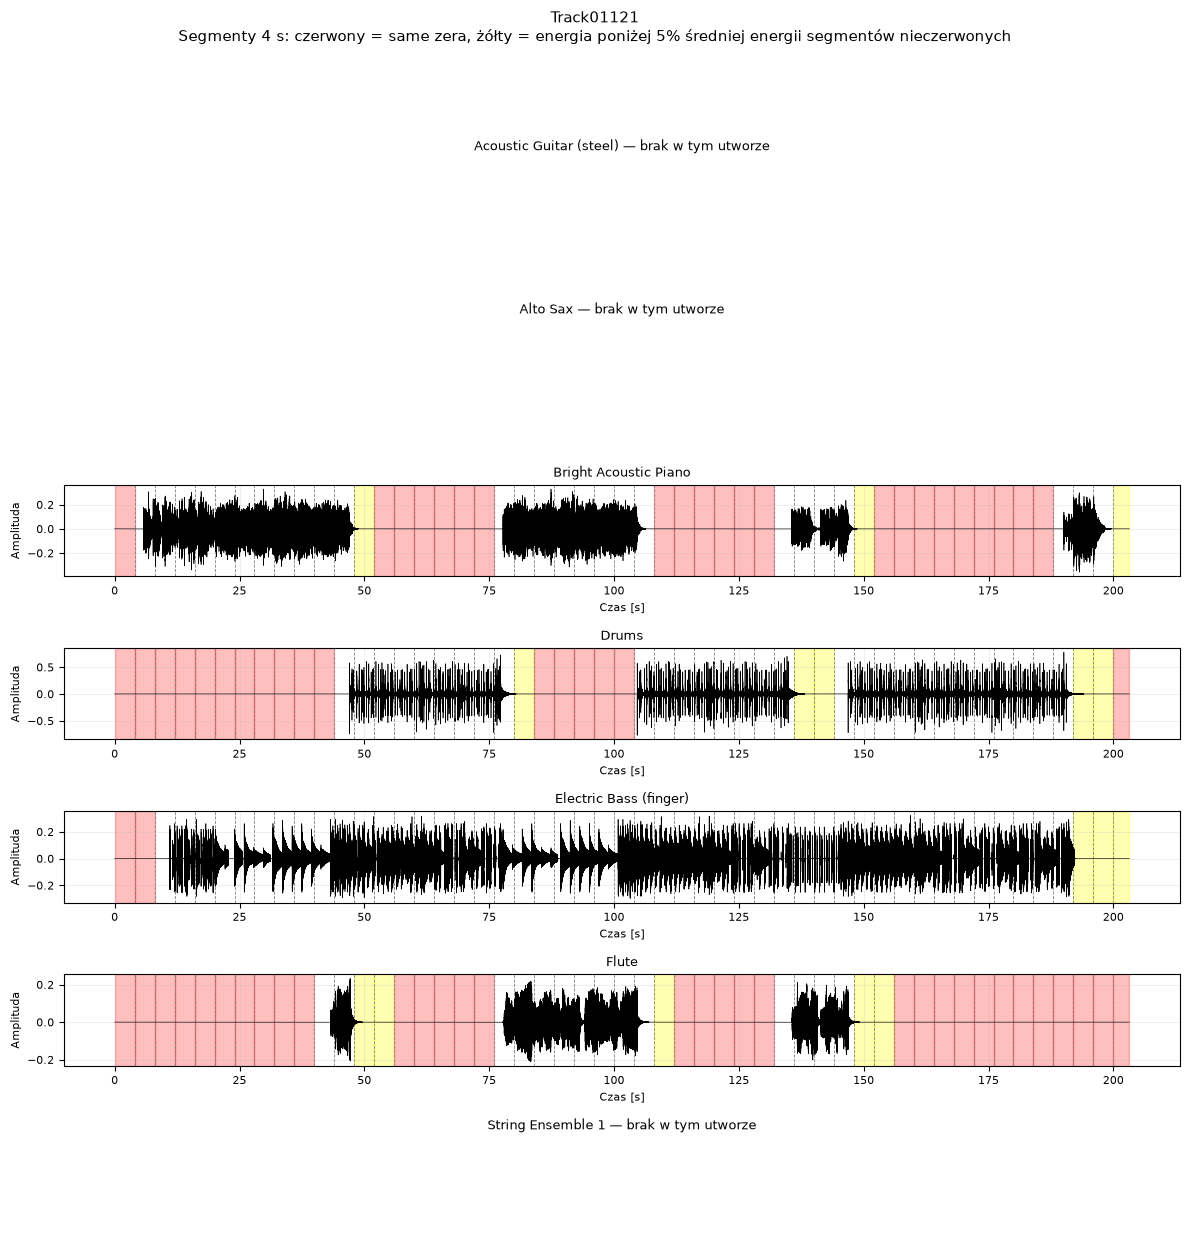

In [31]:

# Konfiguracja
TRACK_NAME = "Track01121"
SEGMENT_LENGTH = 4.0
ENERGY_THRESHOLD = 0.05

# Znajdź metadane wybranego utworu
metadata_path = next(
    path
    for path in SOUND_DIR.rglob("metadata.yaml")
    if Path(
        yaml.safe_load(path.read_text(encoding="utf-8"))["audio_dir"]
    ).parts[0] == TRACK_NAME
)

with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = yaml.safe_load(f)

stems_dir = metadata_path.parent / "stems"
stems = metadata["stems"]

track_name = Path(metadata["audio_dir"]).parts[0]
instruments = sorted(SELECTED_INSTRUMENTS)

fig, axes = plt.subplots(
    len(instruments),
    1,
    figsize=(12, 1.8 * len(instruments)),
    squeeze=False,
)

for ax, instrument in zip(axes[:, 0], instruments):

    # Znajdź instrument w metadanych
    stem_id = next(
        (
            stem_id
            for stem_id, info in stems.items()
            if info.get("midi_program_name") == instrument
        ),
        None,
    )

    if stem_id is None:
        ax.set_title(f"{instrument} — brak w tym utworze", fontsize=9)
        ax.axis("off")
        continue

    # Znajdź plik audio
    number = int(stem_id[1:])

    audio_path = next(
        path
        for path in (
            stems_dir / f"S{number}.flac",
            stems_dir / f"S{number:02d}.flac",
        )
        if path.exists()
    )

    # Wczytaj audio
    audio, sr = sf.read(audio_path)

    if audio.ndim > 1:
        audio = audio.mean(axis=1)

    time_axis = np.arange(len(audio)) / sr
    duration = len(audio) / sr
    segment_samples = int(SEGMENT_LENGTH * sr)

    # Podział na segmenty i obliczenie energii
    segment_data = []

    for start_sample in range(0, len(audio), segment_samples):
        end_sample = min(
            start_sample + segment_samples,
            len(audio),
        )

        segment = audio[start_sample:end_sample]
        segment_mean = np.mean(segment ** 2)

        # Czerwony segment: wszystkie próbki są dokładnie zerowe
        is_silent = np.all(segment == 0)

        segment_data.append(
            (
                start_sample,
                end_sample,
                segment,
                segment_mean,
                is_silent,
            )
        )

    # Średnia energia wszystkich segmentów NIEoznaczonych na czerwono
    non_silent_energies = [
        segment_mean
        for _, _, _, segment_mean, is_silent in segment_data
        if not is_silent
    ]

    if non_silent_energies:
        overall_mean = np.mean(non_silent_energies)
    else:
        overall_mean = 0.0

    # Próg żółtych fragmentów
    threshold = ENERGY_THRESHOLD * overall_mean

    # Wykres przebiegu audio
    ax.plot(
        time_axis,
        audio,
        linewidth=0.45,
        color="black",
        zorder=2,
    )

    # Kolorowanie segmentów
    for (
        start_sample,
        end_sample,
        segment,
        segment_mean,
        is_silent,
    ) in segment_data:

        start_time = start_sample / sr
        end_time = end_sample / sr

        if is_silent:
            # Czerwony: wszystkie próbki są równe zero
            ax.axvspan(
                start_time,
                end_time,
                color="red",
                alpha=0.25,
                zorder=0,
            )

        elif segment_mean < threshold:
            # Żółty: energia poniżej ustalonego progu
            ax.axvspan(
                start_time,
                end_time,
                color="yellow",
                alpha=0.3,
                zorder=0,
            )

    # Granice segmentów
    for boundary in np.arange(
        SEGMENT_LENGTH,
        duration,
        SEGMENT_LENGTH,
    ):
        ax.axvline(
            boundary,
            color="gray",
            linewidth=0.6,
            linestyle="--",
            zorder=1,
        )

    ax.set_title(instrument, fontsize=9)
    ax.set_xlabel("Czas [s]", fontsize=8)
    ax.set_ylabel("Amplituda", fontsize=8)
    ax.tick_params(axis="both", labelsize=8)
    ax.grid(True, alpha=0.2)

fig.suptitle(
    f"{track_name}\n"
    f"Segmenty {SEGMENT_LENGTH:.0f} s: "
    "czerwony = same zera, "
    f"żółty = energia poniżej {ENERGY_THRESHOLD:.0%} "
    "średniej energii segmentów nieczerwonych",
    fontsize=11,
)

fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


In [33]:
# Przygotuj dane do CSV
csv_rows = []

for metadata_path in metadata_files:

    # Znajdź katalog Trackxxxxx
    track_dir = next(
        (
            parent for parent in metadata_path.parents
            if re.fullmatch(r"Track\d+", parent.name)
        ),
        None,
    )

    track_name = track_dir.name

    # Wczytaj metadane
    with metadata_path.open("r", encoding="utf-8") as f:
        metadata = yaml.safe_load(f) or {}

    stems = metadata.get("stems", {})

    # Sprawdź obecność wybranych instrumentów
    instrument_stems = {
        instrument: []
        for instrument in SELECTED_INSTRUMENTS
    }

    for stem_id, stem_info in stems.items():
        instrument = stem_info.get("midi_program_name")

        if instrument in instrument_stems:
            instrument_stems[instrument].append(stem_id)

    # Przygotuj wiersz CSV
    row = {"Track": track_name}

    for instrument in SELECTED_INSTRUMENTS:
        row[instrument] = int(bool(instrument_stems[instrument]))

    csv_rows.append(row)


# Zapisz informacje o instrumentach do CSV
csv_path = BASE_DIR / "instrumenty.csv"

fieldnames = ["Track"] + sorted(SELECTED_INSTRUMENTS)

with csv_path.open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(csv_rows)

# Podsumowanie
print(f"Liczba utworów w CSV: {len(csv_rows)}")
print(f"Plik CSV: {csv_path}")

Liczba utworów w CSV: 1710
Plik CSV: c:\Users\Wiktor\Documents\GitHub\instrument-recognition-project\data_preparation\instrumenty.csv


In [35]:
SEGMENT_LENGTH = 4.0
ENERGY_THRESHOLD = 0.05

SEGMENTS_DIR = BASE_DIR / "generated_segments"
SEGMENTS_DIR.mkdir(parents=True, exist_ok=True)

instruments = sorted(SELECTED_INSTRUMENTS)

csv_path = SEGMENTS_DIR / "instrumenty.csv"

csv_columns = [
    "track_name",
    "segment_start_s",
    "segment_end_s",
    "audio_file",
] + instruments

csv_rows = []

for metadata_path in metadata_files:

    # Znajdź katalog Trackxxxxx
    track_dir = next(
        (
            parent for parent in metadata_path.parents
            if re.fullmatch(r"Track\d+", parent.name)
        ),
        None,
    )

    if track_dir is None:
        continue

    track_name = track_dir.name

    # Wczytaj metadane
    with metadata_path.open("r", encoding="utf-8") as f:
        metadata = yaml.safe_load(f) or {}

    stems = metadata.get("stems", {})

    # Znajdź katalog stems w SOUND_DIR
    relative_dir = metadata_path.parent.relative_to(METADATA_DIR)
    stems_dir = SOUND_DIR / relative_dir / "stems"

    instrument_stems = {}

    for instrument in instruments:
        stem_id = next(
            (
                stem_id
                for stem_id, info in stems.items()
                if info.get("midi_program_name") == instrument
                and info.get("audio_rendered", True)
            ),
            None,
        )

        if stem_id is None:
            continue

        audio_path = stems_dir / f"{stem_id}.flac"

        if not audio_path.is_file():
            print(f"[BRAK FLAC] {track_name}: {audio_path}")
            continue

        audio, sr = sf.read(audio_path, dtype="float32")

        if audio.ndim > 1:
            audio = audio.mean(axis=1)

        segment_samples = int(SEGMENT_LENGTH * sr)
        segment_data = []

        for start_sample in range(0, len(audio), segment_samples):
            end_sample = min(
                start_sample + segment_samples,
                len(audio),
            )

            segment = audio[start_sample:end_sample]
            segment_mean = np.mean(segment ** 2)
            is_silent = np.all(segment == 0)

            segment_data.append(
                {
                    "start_sample": start_sample,
                    "end_sample": end_sample,
                    "mean_energy": segment_mean,
                    "is_silent": is_silent,
                }
            )

        non_silent_energies = [
            segment["mean_energy"]
            for segment in segment_data
            if not segment["is_silent"]
        ]

        overall_mean = (
            np.mean(non_silent_energies)
            if non_silent_energies
            else 0.0
        )

        threshold = ENERGY_THRESHOLD * overall_mean

        instrument_stems[instrument] = {
            "audio": audio,
            "sr": sr,
            "threshold": threshold,
        }

    if not instrument_stems:
        print(f"Pominięto {track_name}: brak dostępnych plików FLAC.")
        continue

    track_output_dir = SEGMENTS_DIR / track_name
    track_output_dir.mkdir(parents=True, exist_ok=True)

    all_stems = list(instrument_stems.values())

    # Sprawdź częstotliwości próbkowania
    sample_rates = {stem["sr"] for stem in all_stems}

    if len(sample_rates) != 1:
        print(
            f"Pominięto {track_name}: "
            "instrumenty mają różne częstotliwości próbkowania."
        )
        continue

    sr = all_stems[0]["sr"]
    segment_samples = int(SEGMENT_LENGTH * sr)

    track_samples = min(
        len(stem["audio"])
        for stem in all_stems
    )

    for start_sample in range(
        0,
        track_samples,
        segment_samples,
    ):
        end_sample = min(
            start_sample + segment_samples,
            track_samples,
        )

        active_instruments = []
        instrument_labels = {
            instrument: 0
            for instrument in instruments
        }

        for instrument, stem in instrument_stems.items():
            segment = stem["audio"][start_sample:end_sample].copy()

            if len(segment) == 0 or np.all(segment == 0):
                continue

            segment_mean = np.mean(segment ** 2)

            if segment_mean >= stem["threshold"]:
                instrument_labels[instrument] = 1
                active_instruments.append((instrument, segment))

        if not active_instruments:
            continue

        start_seconds = start_sample / sr
        end_seconds = end_sample / sr

        segment_dir = track_output_dir / str(int(start_seconds))
        segment_dir.mkdir(parents=True, exist_ok=True)

        for instrument, segment in active_instruments:
            peak = np.max(np.abs(segment))

            if peak > 1.0:
                segment /= peak

            sf.write(
                segment_dir / f"{instrument}.flac",
                segment,
                sr,
                format="FLAC",
                subtype="PCM_16",
            )

        first_instrument = active_instruments[0][0]

        audio_filename = (
            f"{track_name}/{int(start_seconds)}/{first_instrument}.flac"
        )

        csv_rows.append({
            "track_name": track_name,
            "segment_start_s": start_seconds,
            "segment_end_s": end_seconds,
            "audio_file": audio_filename,
            **instrument_labels,
        })

    print(f"Przetworzono: {track_name}")


# Zapis CSV
with csv_path.open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=csv_columns)
    writer.writeheader()
    writer.writerows(csv_rows)

print(f"Liczba zapisanych segmentów: {len(csv_rows)}")
print(f"Zapisano plik CSV: {csv_path}")

Przetworzono: Track01876
Przetworzono: Track01877
Przetworzono: Track01878
Przetworzono: Track01880
Przetworzono: Track01881
Przetworzono: Track01882
Przetworzono: Track01883
Przetworzono: Track01884
Przetworzono: Track01886
Przetworzono: Track01887
Przetworzono: Track01888
Przetworzono: Track01889
Przetworzono: Track01891
Przetworzono: Track01892
Przetworzono: Track01893
Przetworzono: Track01895
Przetworzono: Track01896
Przetworzono: Track01897
Przetworzono: Track01898
Przetworzono: Track01899
Przetworzono: Track01900
Przetworzono: Track01901
Przetworzono: Track01902
Przetworzono: Track01903
Przetworzono: Track01904
Przetworzono: Track01905
Przetworzono: Track01906
Przetworzono: Track01907
Przetworzono: Track01908
Przetworzono: Track01911
Przetworzono: Track01913
Przetworzono: Track01916
Przetworzono: Track01917
Przetworzono: Track01918
Przetworzono: Track01920
Przetworzono: Track01925
Przetworzono: Track01927
Przetworzono: Track01928
Przetworzono: Track01929
Przetworzono: Track01930


In [ ]:
COMBINATIONS_DIR = BASE_DIR / "generated_combinations"
COMBINATIONS_DIR.mkdir(parents=True, exist_ok=True)

counts = Counter()

track_dirs = sorted(
    path for path in SEGMENTS_DIR.iterdir()
    if path.is_dir() and path.name.startswith("Track")
)

for track_dir in track_dirs:
    segment_dirs = sorted(
        (path for path in track_dir.iterdir() if path.is_dir()),
        key=lambda path: int(path.name) if path.name.isdigit() else -1,
    )

    for segment_dir in segment_dirs:
        # Instrumenty, dla których istnieje plik w danym fragmencie.
        present_instruments = sorted(
            path.stem
            for path in segment_dir.glob("*.flac")
        )

        if not present_instruments:
            continue

        # Zlicz wszystkie niepuste kombinacje bez miksowania audio.
        for size in range(1, len(present_instruments) + 1):
            for combo in combinations(present_instruments, size):
                counts[combo] += 1

counts_path = COMBINATIONS_DIR / "licznosci_kombinacji.csv"

with open(counts_path, "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.writer(f)
    writer.writerow(["kombinacja", "liczba_instrumentow", "licznosc"])

    for combo, count in sorted(
        counts.items(),
        key=lambda item: (len(item[0]), item[0]),
    ):
        writer.writerow([
            " + ".join(combo),
            len(combo),
            count,
        ])
        print(f"{' + '.join(combo)}: {count}")

print(f"Liczba kombinacji, które faktycznie wystąpiły: {len(counts)}")
print(f"Zapisano zestawienie: {counts_path}")


Acoustic Guitar (steel): 36918
Alto Sax: 6983
Bright Acoustic Piano: 27238
Drums: 92109
Electric Bass (finger): 45944
Flute: 6912
String Ensemble 1: 27127
Acoustic Guitar (steel) + Alto Sax: 2129
Acoustic Guitar (steel) + Bright Acoustic Piano: 10490
Acoustic Guitar (steel) + Drums: 33667
Acoustic Guitar (steel) + Electric Bass (finger): 17990
Acoustic Guitar (steel) + Flute: 2707
Acoustic Guitar (steel) + String Ensemble 1: 10030
Alto Sax + Bright Acoustic Piano: 2018
Alto Sax + Drums: 6620
Alto Sax + Electric Bass (finger): 3423
Alto Sax + Flute: 252
Alto Sax + String Ensemble 1: 1823
Bright Acoustic Piano + Drums: 24560
Bright Acoustic Piano + Electric Bass (finger): 12681
Bright Acoustic Piano + Flute: 1378
Bright Acoustic Piano + String Ensemble 1: 7280
Drums + Electric Bass (finger): 43912
Drums + Flute: 6308
Drums + String Ensemble 1: 24917
Electric Bass (finger) + Flute: 3864
Electric Bass (finger) + String Ensemble 1: 11138
Flute + String Ensemble 1: 2139
Acoustic Guitar (stee

In [37]:
COMBINATIONS_DIR = BASE_DIR / "generated_combinations"
COMBINATIONS_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_CSV = COMBINATIONS_DIR / "plan_generowania.csv"
SUMMARY_CSV = COMBINATIONS_DIR / "plan_generowania_licznosci.csv"

TARGET_PER_CATEGORY = 100

# Zbierz fragmenty źródłowe dla każdej kombinacji instrumentów.
examples_by_combo = defaultdict(list)

track_dirs = sorted(
    path for path in SEGMENTS_DIR.iterdir()
    if path.is_dir() and path.name.startswith("Track")
)

for track_dir in track_dirs:
    track_name = track_dir.name

    segment_dirs = sorted(
        (
            path for path in track_dir.iterdir()
            if path.is_dir() and path.name.isdigit()
        ),
        key=lambda path: int(path.name),
    )

    for segment_dir in segment_dirs:
        segment_start_s = int(segment_dir.name)

        instrument_files = {
            path.stem: path
            for path in segment_dir.glob("*.flac")
        }

        present_instruments = sorted(instrument_files)

        if not present_instruments:
            continue

        # Każdy niepusty podzbiór obecnych instrumentów.
        for size in range(1, len(present_instruments) + 1):
            for combo in combinations(present_instruments, size):
                examples_by_combo[combo].append({
                    "track_name": track_name,
                    "segment_start_s": segment_start_s,
                    "source_files": [
                        str(
                            instrument_files[instrument].relative_to(
                                SEGMENTS_DIR
                            )
                        )
                        for instrument in combo
                    ],
                })

# Przygotuj plan: maksymalnie 100 różnych fragmentów na kategorię.
plan_rows = []
category_summary = []

all_instruments = sorted({
    instrument
    for combo in examples_by_combo
    for instrument in combo
})

for combo in sorted(examples_by_combo, key=lambda c: (len(c), c)):
    # Deduplikacja po utworze i sekundzie początku.
    unique_examples = {}
    for example in examples_by_combo[combo]:
        key = (
            example["track_name"],
            example["segment_start_s"],
        )
        unique_examples[key] = example

    examples = list(unique_examples.values())
    random.shuffle(examples)

    selected_examples = examples[:TARGET_PER_CATEGORY]

    category_name = " + ".join(combo)

    category_summary.append({
        "kombinacja": category_name,
        "dostepne_fragmenty": len(examples),
        "zaplanowane_przyklady": len(selected_examples),
    })

    for example in selected_examples:
        track_name = example["track_name"]
        segment_start_s = example["segment_start_s"]

        # Unikalny numer kombinacji dla danego utworu i fragmentu.
        # Każdy wybrany wiersz otrzymuje inną nazwę pliku.
        output_index = len(plan_rows)
        filename = (
            f"{track_name}_{segment_start_s}_{output_index}.flac"
        )

        row = {
            "output_file": filename,
            "track_name": track_name,
            "segment_start_s": segment_start_s,
            "combination": category_name,
            "combination_size": len(combo),
            "source_files": " | ".join(example["source_files"]),
        }

        for instrument in all_instruments:
            row[instrument] = int(instrument in combo)

        plan_rows.append(row)

# Zapis planu generowania.
base_columns = [
    "output_file",
    "track_name",
    "segment_start_s",
    "combination",
    "combination_size",
    "source_files",
]

csv_columns = base_columns + all_instruments

with open(OUTPUT_CSV, "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(f, fieldnames=csv_columns)
    writer.writeheader()
    writer.writerows(plan_rows)

# Zapis liczności każdej kategorii.
with open(SUMMARY_CSV, "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "kombinacja",
            "dostepne_fragmenty",
            "zaplanowane_przyklady",
        ],
    )
    writer.writeheader()
    writer.writerows(category_summary)

print(f"Liczba kategorii obecnych w danych: {len(category_summary)}")
print(f"Liczba zaplanowanych nagrań: {len(plan_rows)}")
print(f"Plan zapisano w: {OUTPUT_CSV}")
print(f"Liczności zapisano w: {SUMMARY_CSV}")

Liczba kategorii obecnych w danych: 127
Liczba zaplanowanych nagrań: 11011
Plan zapisano w: c:\Users\Wiktor\Documents\GitHub\instrument-recognition-project\data_preparation\generated_combinations\plan_generowania.csv
Liczności zapisano w: c:\Users\Wiktor\Documents\GitHub\instrument-recognition-project\data_preparation\generated_combinations\plan_generowania_licznosci.csv


In [ ]:
SEGMENTS_DIR = BASE_DIR / "generated_segments"
COMBINATIONS_DIR = BASE_DIR / "generated_combinations"

PLAN_CSV = COMBINATIONS_DIR / "plan_generowania.csv"
OUTPUT_CSV = COMBINATIONS_DIR / "etykiety.csv"

with open(PLAN_CSV, "r", newline="", encoding="utf-8-sig") as f:
    plan_rows = list(csv.DictReader(f))

metadata_columns = {
    "output_file",
    "track_name",
    "segment_start_s",
    "combination",
    "combination_size",
    "source_files",
}

instruments = [
    column
    for column in (plan_rows[0].keys() if plan_rows else [])
    if column not in metadata_columns
]

label_rows = []

for row in plan_rows:
    output_path = COMBINATIONS_DIR / row["output_file"]

    source_files = [
        SEGMENTS_DIR / path.strip()
        for path in row["source_files"].split("|")
        if path.strip()
    ]

    audio_parts = []
    sr = None

    for source_path in source_files:
        audio, sr = sf.read(source_path, dtype="float32")

        if audio.ndim > 1:
            audio = audio.mean(axis=1)

        audio_parts.append(audio)

    max_length = max(len(audio) for audio in audio_parts)
    mix = np.zeros(max_length, dtype=np.float32)

    for audio in audio_parts:
        mix[:len(audio)] += audio

    peak = np.max(np.abs(mix))
    if peak > 1.0:
        mix /= peak

    sf.write(
        output_path,
        mix,
        sr,
        format="FLAC",
        subtype="PCM_16",
    )

    label_row = {"audio_file": row["output_file"]}

    for instrument in instruments:
        label_row[instrument] = int(row[instrument] == "1")

    label_rows.append(label_row)
    print(f"Wygenerowano: {row['output_file']}")

with open(OUTPUT_CSV, "w", newline="", encoding="utf-8-sig") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["audio_file"] + instruments,
    )
    writer.writeheader()
    writer.writerows(label_rows)

print(f"Wygenerowano nagrań: {len(label_rows)}")
print(f"Zapisano etykiety: {OUTPUT_CSV}")


Wygenerowano: Track00409_176_0.flac
Wygenerowano: Track01195_216_1.flac
Wygenerowano: Track00161_112_2.flac
Wygenerowano: Track00643_16_3.flac
Wygenerowano: Track00659_136_4.flac
Wygenerowano: Track00630_148_5.flac
Wygenerowano: Track00076_92_6.flac
Wygenerowano: Track00472_36_7.flac
Wygenerowano: Track00572_216_8.flac
Wygenerowano: Track00938_108_9.flac
Wygenerowano: Track01559_76_10.flac
Wygenerowano: Track01154_168_11.flac
Wygenerowano: Track01978_136_12.flac
Wygenerowano: Track00857_48_13.flac
Wygenerowano: Track01559_116_14.flac
Wygenerowano: Track00124_20_15.flac
Wygenerowano: Track02014_108_16.flac
Wygenerowano: Track00818_112_17.flac
Wygenerowano: Track00354_112_18.flac
Wygenerowano: Track01737_204_19.flac
Wygenerowano: Track01950_16_20.flac
Wygenerowano: Track00575_72_21.flac
Wygenerowano: Track01488_4_22.flac
Wygenerowano: Track01957_68_23.flac
Wygenerowano: Track01753_168_24.flac
Wygenerowano: Track01017_128_25.flac
Wygenerowano: Track01026_24_26.flac
Wygenerowano: Track0166

In [ ]:
NOISE_LEVEL = 0.5
NOISE_DIR = BASE_DIR / "noisy_sounds"
NOISE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Dodawanie białego szumu do wcześniej wygenerowanych fragmentów

audio_files = sorted(COMBINATIONS_DIR.glob("*.flac"))

for audio_path in audio_files:
    audio, sr = sf.read(audio_path, dtype="float32")

    noise = np.random.normal(
        0,
        NOISE_LEVEL,
        size=audio.shape
    ).astype(np.float32)

    noisy_audio = np.clip(audio + noise, -1.0, 1.0)

    output_path = NOISE_OUTPUT_DIR / audio_path.name

    sf.write(
        output_path,
        noisy_audio,
        sr,
        format="FLAC",
        subtype="PCM_16"
    )

# 2. Generowanie nagrań zawierających wyłącznie biały szum

sr = sf.info(audio_files[0]).samplerate
num_samples = int(SEGMENT_LENGTH * sr)

for i in range(1, TARGET_PER_CATEGORY + 1):
    white_noise = np.random.normal(
        0,
        NOISE_LEVEL,
        size=num_samples
    ).astype(np.float32)

    output_path = NOISE_OUTPUT_DIR / "Track00000.flac"

    sf.write(
        output_path,
        white_noise,
        sr,
        format="FLAC",
        subtype="PCM_16"
    )

print(f"Zapisano {len(audio_files)} zaszumionych nagrań.")
print(f"Wygenerowano {TARGET_PER_CATEGORY} nagrań z samym białym szumem.")
print(f"Pliki zapisano w: {NOISE_OUTPUT_DIR}")

Zapisano 11011 zaszumionych nagrań.
Wygenerowano 100 nagrań z samym białym szumem.
Pliki zapisano w: c:\Users\Wiktor\Documents\GitHub\instrument-recognition-project\data_preparation\noisy_sounds


In [45]:
DATASET_DIR = BASE_DIR / "dataset"

TRAIN_DIR = DATASET_DIR / "train"
VALIDATION_DIR = DATASET_DIR / "validation"
TEST_DIR = DATASET_DIR / "test"

TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
TEST_RATIO = 0.15

LABELS_CSV = COMBINATIONS_DIR / "etykiety.csv"

TRAIN_DIR.mkdir(parents=True, exist_ok=True)
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)
TEST_DIR.mkdir(parents=True, exist_ok=True)

with open(PLAN_CSV, "r", newline="", encoding="utf-8-sig") as f:
    plan_rows = list(csv.DictReader(f))

with open(LABELS_CSV, "r", newline="", encoding="utf-8-sig") as f:
    label_reader = csv.DictReader(f)
    label_rows = list(label_reader)
    label_columns = label_reader.fieldnames

labels_by_file = {
    row["audio_file"]: row
    for row in label_rows
}

groups = {}

for row in plan_rows:
    combination = row["combination"]
    groups.setdefault(combination, []).append(row)

train_rows = []
validation_rows = []
test_rows = []

for combination, rows in groups.items():
    indices = np.random.permutation(len(rows))
    shuffled_rows = [rows[i] for i in indices]

    n = len(shuffled_rows)
    n_train = int(round(n * TRAIN_RATIO))
    n_validation = int(round(n * VALIDATION_RATIO))

    train_rows.extend(shuffled_rows[:n_train])
    validation_rows.extend(
        shuffled_rows[n_train:n_train + n_validation]
    )
    test_rows.extend(shuffled_rows[n_train + n_validation:])

np.random.shuffle(train_rows)
np.random.shuffle(validation_rows)
np.random.shuffle(test_rows)

datasets = [
    ("train", TRAIN_DIR, train_rows),
    ("validation", VALIDATION_DIR, validation_rows),
    ("test", TEST_DIR, test_rows),
]

all_label_rows = []

for dataset_name, dataset_dir, rows in datasets:
    for row in rows:
        audio_file = row["output_file"]

        source_path = NOISE_DIR / audio_file
        destination_path = dataset_dir / audio_file

        destination_path.write_bytes(source_path.read_bytes())

        label = labels_by_file[audio_file].copy()

        all_label_rows.append({
            "dataset": dataset_name,
            **label,
        })

with open(
    DATASET_DIR / "etykiety.csv",
    "w",
    newline="",
    encoding="utf-8-sig",
) as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["dataset"] + label_columns,
    )
    writer.writeheader()
    writer.writerows(all_label_rows)

total = len(plan_rows)

print(f"Wszystkie nagrania: {total}")

for dataset_name, dataset_dir, rows in datasets:
    percentage = len(rows) / total * 100 if total else 0

    print(
        f"{dataset_name}: {len(rows)} "
        f"({percentage:.2f}%)"
    )
    print(f"Folder: {dataset_dir}")

print(f"Plik etykiet: {DATASET_DIR / 'etykiety.csv'}")

Wszystkie nagrania: 11011
train: 7709 (70.01%)
Folder: c:\Users\Wiktor\Documents\GitHub\instrument-recognition-project\data_preparation\dataset\train
validation: 1646 (14.95%)
Folder: c:\Users\Wiktor\Documents\GitHub\instrument-recognition-project\data_preparation\dataset\validation
test: 1656 (15.04%)
Folder: c:\Users\Wiktor\Documents\GitHub\instrument-recognition-project\data_preparation\dataset\test
Plik etykiet: c:\Users\Wiktor\Documents\GitHub\instrument-recognition-project\data_preparation\dataset\etykiety.csv
